# 12 Circuits with free parameters

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/12_parameters.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/12_parameters.ipynb)

When the same circuit runs for many sets of angles, such as the steps of a variational loop or the tiles of an image, cut it **once** with symbolic Qiskit `Parameter`s and give the values
afterwards. The cut is planned once and the values are bound where each circuit is built, so the planning cost is not repeated per set of values.

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
%matplotlib inline
import time

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
import Qdislib as qd

theta, phi = Parameter("theta"), Parameter("phi")


def template():
    qc = QuantumCircuit(6)
    for q in range(6):
        qc.ry(theta if q % 2 else phi, q)
    for q in range(5):
        qc.cz(q, q + 1)
    for q in range(6):
        qc.ry(phi if q % 2 else theta, q)
    return qc


circuit = template()
cut = qd.find_cut(circuit, max_qubits=3, wire_cut=False)
print(circuit.parameters, cut)

ParameterView([Parameter(phi), Parameter(theta)]) ['CZ_9']


## `parameter_values=`

Every cutting function takes it and returns one result per set of values, in a list. Values go in the order of `circuit.parameters`, which is sorted by name, or as a dict. The parameters can be anywhere but in a **cut gate**: its angle sets the cut's terms and weights, so it must be a number.

In [3]:
values = [[0.1, 0.2], [0.3, 0.4], [1.1, 0.5]]    # [phi, theta]
print(qd.circuit_cutting(circuit, cut, "Z" * 6, shots=None, parameter_values=values))
print([qd.analytical_solution(circuit.assign_parameters(dict(zip(circuit.parameters, v))), "Z" * 6) for v in values])
print(qd.circuit_cutting(circuit, cut, "Z" * 6, shots=4000, seed=1, parameter_values=values, error=True))
print(qd.circuit_cutting_sampling(circuit, cut, shots=None, parameter_values=values[:1], qubits=[0, 5]))

[0.7564287617936787, 0.14676500407109858, 0.07433012267073824]
[0.7564287617936795, 0.14676500407109921, 0.07433012267073826]


[0.760696 ± 0.0094, 0.145988 ± 0.01, 0.0751857 ± 0.0046]
[{'00': 0.9560769067539654, '10': 0.021640881097303184, '01': 0.02178901594253845, '11': 0.0004931962061928972}]


It combines with `sync=False` (one future per set of values), `circuits_per_task=` and `error=`. Each set gets its own seed stream from `seed`.

## What it saves

Compared with cutting each bound circuit on its own. What it saves is planning on the master, not simulation. In a serial run like this one, of a small circuit, the two take about the same time. The saving shows when there are many circuits under PyCOMPSs: the changelog records that per-circuit planning dominated the master in a QHED image run of 578 tile circuits on MareNostrum 5.

cut once:  0.43 s


cut each:  0.52 s
largest difference: 0.0


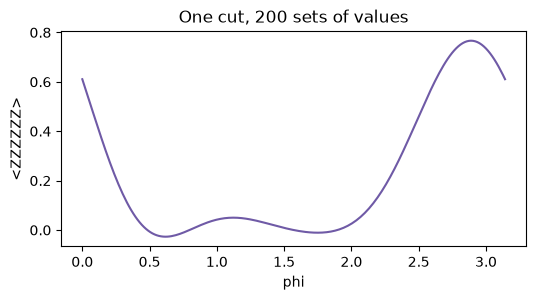

In [4]:
sweep = [[float(a), 0.4] for a in np.linspace(0, np.pi, 200)]

start = time.time()
once = qd.circuit_cutting(circuit, cut, "Z" * 6, shots=None, parameter_values=sweep)
print(f"cut once:  {time.time() - start:.2f} s")

start = time.time()
each = [qd.circuit_cutting(circuit.assign_parameters(dict(zip(circuit.parameters, v))), cut, "Z" * 6, shots=None) for v in sweep]
print(f"cut each:  {time.time() - start:.2f} s")
print("largest difference:", max(abs(a - b) for a, b in zip(once, each)))

plt.figure(figsize=(6, 2.8))
plt.plot([v[0] for v in sweep], once, color="#6f5aa6")
plt.xlabel("phi")
plt.ylabel("<ZZZZZZ>")
plt.title("One cut, 200 sets of values")
plt.show()

## The three-step form

`subs.bind(values)` gives the same list of subcircuits with values bound, as `{parameter: value}` or a list in `subs.parameters` order. An unbound list still gives its circuits with their parameters, to bind yourself, for instance on a device with its own parameter sweeps.

In [5]:
subs = qd.circuit_cutting_subcircuits(circuit, cut, "Z" * 6)
print(subs.parameters, len(subs), "subcircuits")

bound = subs.bind({theta: 0.4, phi: 1.1})
print(f"{bound.reconstruct([qd.expectation_value(s, shots=4000, seed=i) for i, s in enumerate(bound)]):+.4f}")

print(subs.circuits("qiskit")[0].parameters)

('phi', 'theta') 12 subcircuits
+0.0551
ParameterView([Parameter(phi), Parameter(theta)])


## A small optimisation loop

Here a classical optimiser drives the cut. The objective is a Hamiltonian, whose terms are grouped (notebook 05), and every step runs on the plan made at the start. For a complete worked example, with a molecule, see **application 01**.

37 evaluations, minimum -0.2607 at [1.131 1.131]


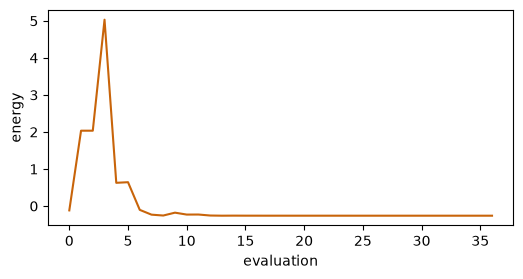

In [6]:
from scipy.optimize import minimize

hamiltonian = [(1.0, "ZZIIII"), (1.0, "IZZIII"), (1.0, "IIZZII"), (1.0, "IIIZZI"), (1.0, "IIIIZZ"),
               (0.5, "XIIIII"), (0.5, "IXIIII"), (0.5, "IIXIII"), (0.5, "IIIXII"), (0.5, "IIIIXI"), (0.5, "IIIIIX")]
trace = []


def energy(values):
    result = qd.circuit_cutting(circuit, cut, hamiltonian, shots=None, parameter_values=[list(values)])[0]
    trace.append(result)
    return result


result = minimize(energy, x0=[1.0, 1.0], method="COBYLA", options={"maxiter": 60})
print(f"{result.nfev} evaluations, minimum {result.fun:+.4f} at {np.round(result.x, 3)}")
plt.figure(figsize=(6, 2.8))
plt.plot(trace, color="#c8640a")
plt.xlabel("evaluation")
plt.ylabel("energy")
plt.show()

Next: **13 Packing**.